# Human PBMCs (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-12
> - Modified: 2025-12-21
> - https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high

# Experimental Design

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donor | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 25-30 | Healthy | 10X 3' V3.1 scRNA-seq | AllCells |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger 6.1.0 with --expect-cells = 10000

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(DropletUtils))
suppressPackageStartupMessages(library(scuttle))
suppressPackageStartupMessages(library(scater))
suppressPackageStartupMessages(library(scran))
suppressPackageStartupMessages(library(bluster))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [45]:
scrna <- file.path(data_dir, "matrix", "filtered_feature_bc_matrix.h5") |>
    read10xCounts(sample.names = "PBMCs")

In [46]:
rownames(scrna) <- scuttle::uniquifyFeatureNames(
    rowData(scrna)$ID, rowData(scrna)$Symbol)

# 2. Quality Control

In [47]:
scrna

class: SingleCellExperiment 
dim: 36601 11996 
metadata(1): Samples
assays(1): counts
rownames(36601): MIR1302-2HG FAM138A ... AC007325.4 AC007325.2
rowData names(3): ID Symbol Type
colnames: NULL
colData names(2): Sample Barcode
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

## 1). Calculate Metrics

In [48]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )

    obj <- addPerCellQCMetrics(
        obj, subsets = list(
            mt = grepl(mt_pattern, rownames(obj)), 
            rp = grepl(rp_pattern, rownames(obj)), 
            hp = grepl(hb_pattern, rownames(obj))))

    return(obj)
}

In [49]:
# qc_metrics <- perCellQCMetrics(
#     scrna, subsets = list(
#         Mito = grepl(mt_pattern, rownames(scrna)), 
#         rp = grepl(rp_pattern, rownames(scrna)), 
#         hp = grepl(hb_pattern, rownames(scrna))))

In [50]:
scrna <- calculate_qc_metrics(scrna, species = "human")

## 2). Visualizate Metrics

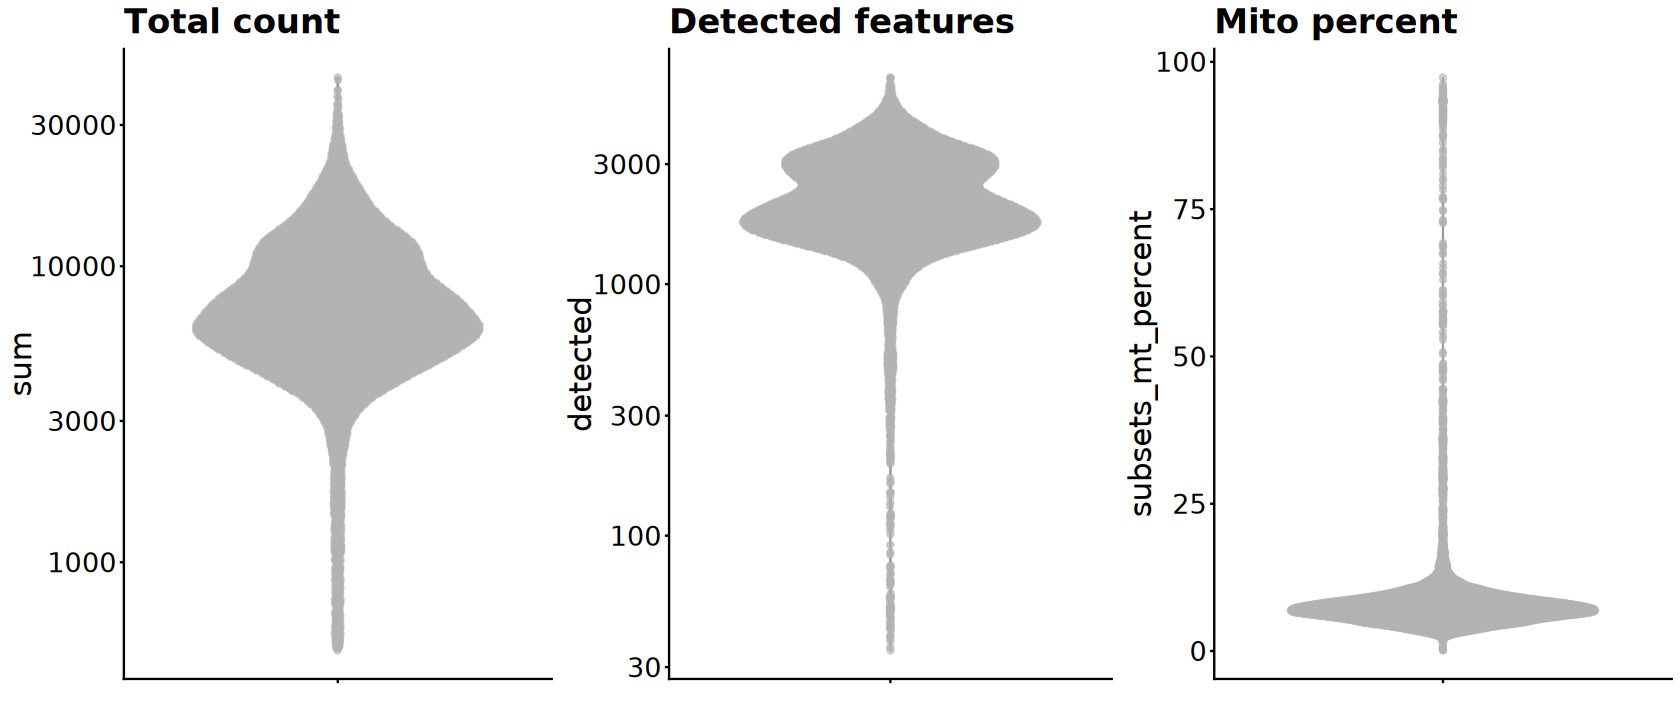

In [51]:
p1 <- plotColData(scrna, y = "sum") + 
    scale_y_log10() + ggtitle("Total count") +
    theme(plot.title = element_text(size = 20), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))
p2 <- plotColData(scrna, y = "detected") + 
    scale_y_log10() + ggtitle("Detected features") +
    theme(plot.title = element_text(size = 20), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))
p3 <- plotColData(scrna, y = "subsets_mt_percent") + 
    ggtitle("Mito percent") +
    theme(plot.title = element_text(size = 20), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, p3, ncol = 3)

In [52]:
scrna

class: SingleCellExperiment 
dim: 36601 11996 
metadata(1): Samples
assays(1): counts
rownames(36601): MIR1302-2HG FAM138A ... AC007325.4 AC007325.2
rowData names(6): ID Symbol ... subsets_rp subsets_hp
colnames: NULL
colData names(14): Sample Barcode ... subsets_hp_percent total
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

## 6). Filtering Low-quality Cells

In [53]:
qc.lib <- scrna$sum < 600
qc.nexprs <- scrna$detected < 1000
qc.mito <- scrna$subsets_mt_percent > 15
qc.hb <- scrna$subsets_hp_percent > 1
discard <- qc.lib | qc.nexprs | qc.mito | qc.hb

In [54]:
scrna <- scrna[, !discard]
scrna

class: SingleCellExperiment 
dim: 36601 11405 
metadata(1): Samples
assays(1): counts
rownames(36601): MIR1302-2HG FAM138A ... AC007325.4 AC007325.2
rowData names(6): ID Symbol ... subsets_rp subsets_hp
colnames: NULL
colData names(14): Sample Barcode ... subsets_hp_percent total
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [18]:
reasons <- perCellQCFilters(
    scrna, sub.fields=c("subsets_mt_percent", "subsets_hp_percent"))

In [19]:
colSums(as.matrix(reasons))

low_lib_size          low_n_features high_subsets_mt_percent 
                    307                     245                     525 
high_subsets_hp_percent                 discard 
                    113                     669

In [33]:
# MAD
both.feature <- isOutlier(
    scrna$sum, nmads = 3, type = "lower")
both.count <- isOutlier(
    scrna$detected, nmads = 3, type = "lower")
high.mito <- isOutlier(
    scrna$subsets_mt_percent, nmads = 3, type = "higher")

In [34]:
table(both.feature)
table(both.count)
table(high.mito)

both.feature
FALSE 
11996 

both.count
FALSE 
11996 

high.mito
FALSE  TRUE 
11471   525 

In [ ]:
sce <- scuttle::addPerCellQC(sce)
sce <- scuttle::addPerFeatureQC(sce)

In [ ]:
is.mito <- grepl("^MT-", rowData(sce)$Symbol)
qcstats <- perCellQCMetrics(sce, subsets = list(Mito = is.mito))
filtered <- quickPerCellQC(qcstats, percent_subsets = "subsets_Mito_percent")
sce <- sce[, !filtered$discard]

# 3. Normalization

## a). LogNormalize

### 1). Normalizate
log1p(counts per 10k)

In [58]:
scrna <- logNormCounts(scrna)
scrna

### 2). Feature selection

Number of features: 2000 ~ 5000

In [61]:
# Feature selection.
dec <- scran::modelGeneVar(scrna)
hvg <- scran::getTopHVGs(dec, n = 2000)

# 4. Dimensionality Reduction

In [62]:
scrna <- fixedPCA(scrna, rank = 50, subset.row = hvg)

class: SingleCellExperiment 
dim: 36601 11405 
metadata(1): Samples
assays(2): counts logcounts
rownames(36601): MIR1302-2HG FAM138A ... AC007325.4 AC007325.2
rowData names(6): ID Symbol ... subsets_rp subsets_hp
colnames: NULL
colData names(15): Sample Barcode ... total sizeFactor
reducedDimNames(1): PCA
mainExpName: NULL
altExpNames(0):

In [ ]:
# # PCA
# set.seed(1234)
# sce <- scater::runPCA(sce, ncomponents = 50, subset_row = hvg)

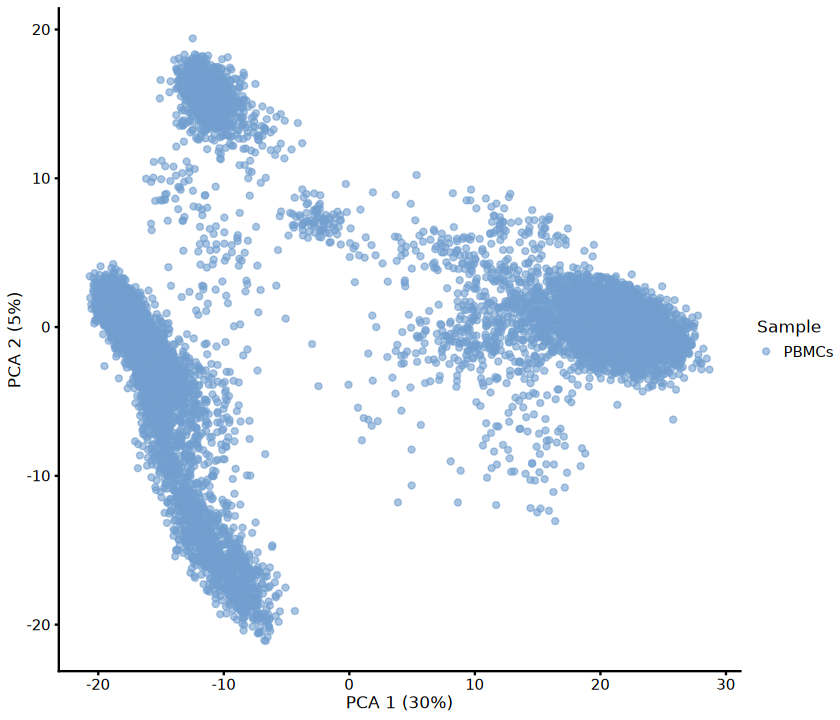

In [83]:
options(repr.plot.width = 7, repr.plot.height = 6)
plotReducedDim(scrna, dimred = "PCA", color_by = "Sample")

Warning message in data.frame(gg1$all, df_to_plot[, -reddim_cols]):
“row names were found from a short variable and have been discarded”


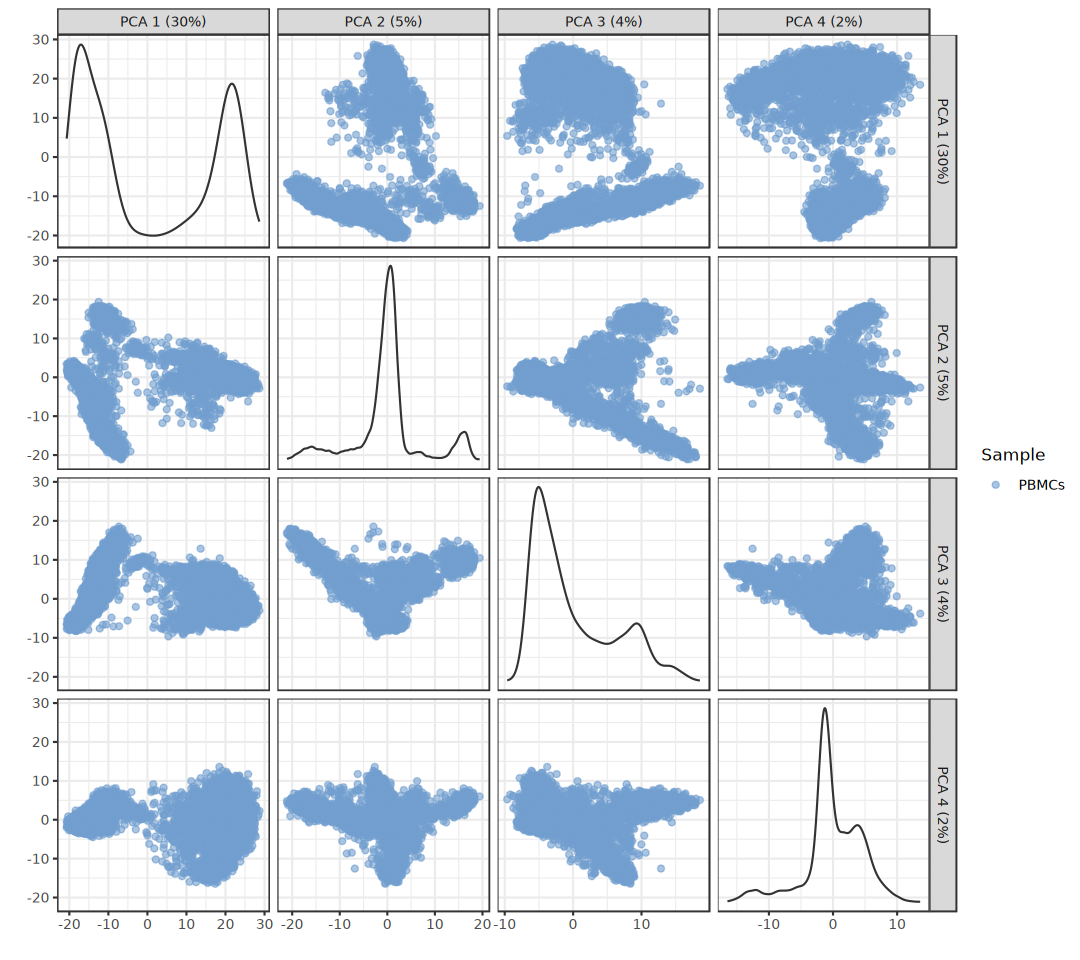

In [84]:
options(repr.plot.width = 9, repr.plot.height = 8)
plotReducedDim(scrna, dimred = "PCA", ncomponents = 4,
               color_by = "Sample")

In [78]:
# Estimating PCA dimensionality
pca_var <- attr(reducedDim(scrna), "percentVar")
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 12


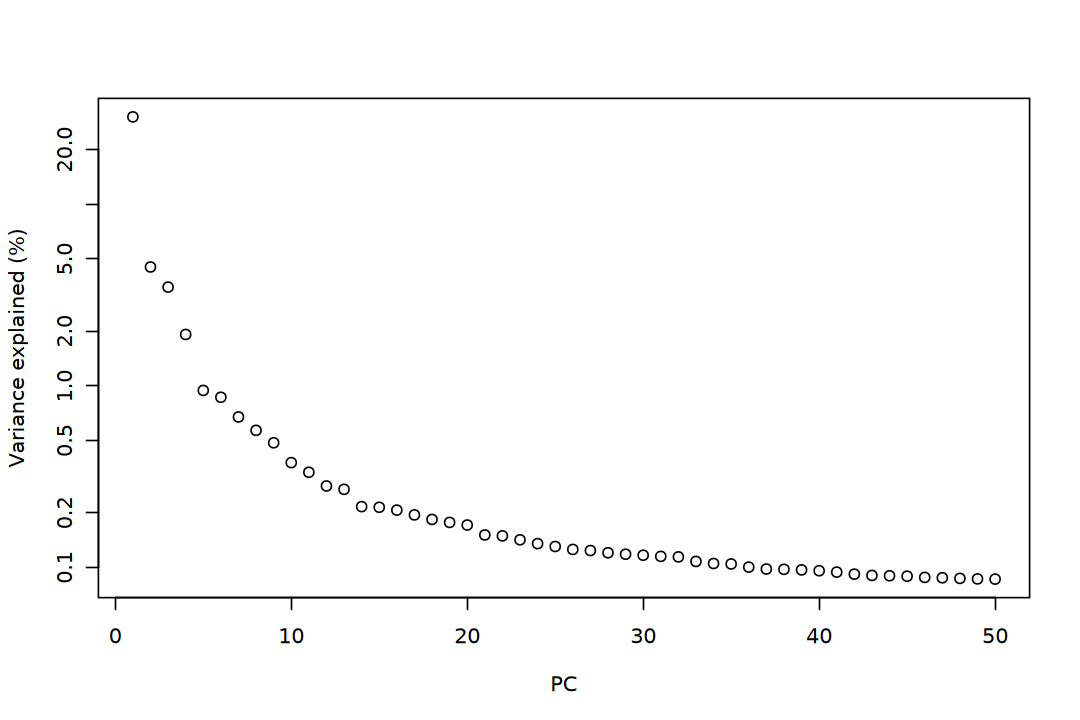

In [79]:
options(repr.plot.width = 9, repr.plot.height = 6)
plot(pca_var, log = "y", xlab = "PC", ylab = "Variance explained (%)")

## Non-linear methods for visualization

In [97]:
set.seed(123)
scrna <- runUMAP(
    scrna, dimred = "PCA", n_neighbors = 30, min_dist = 0.3)

In [98]:
set.seed(123)
scrna <- runTSNE(
    scrna, dimred = "PCA", perplexity = 30)

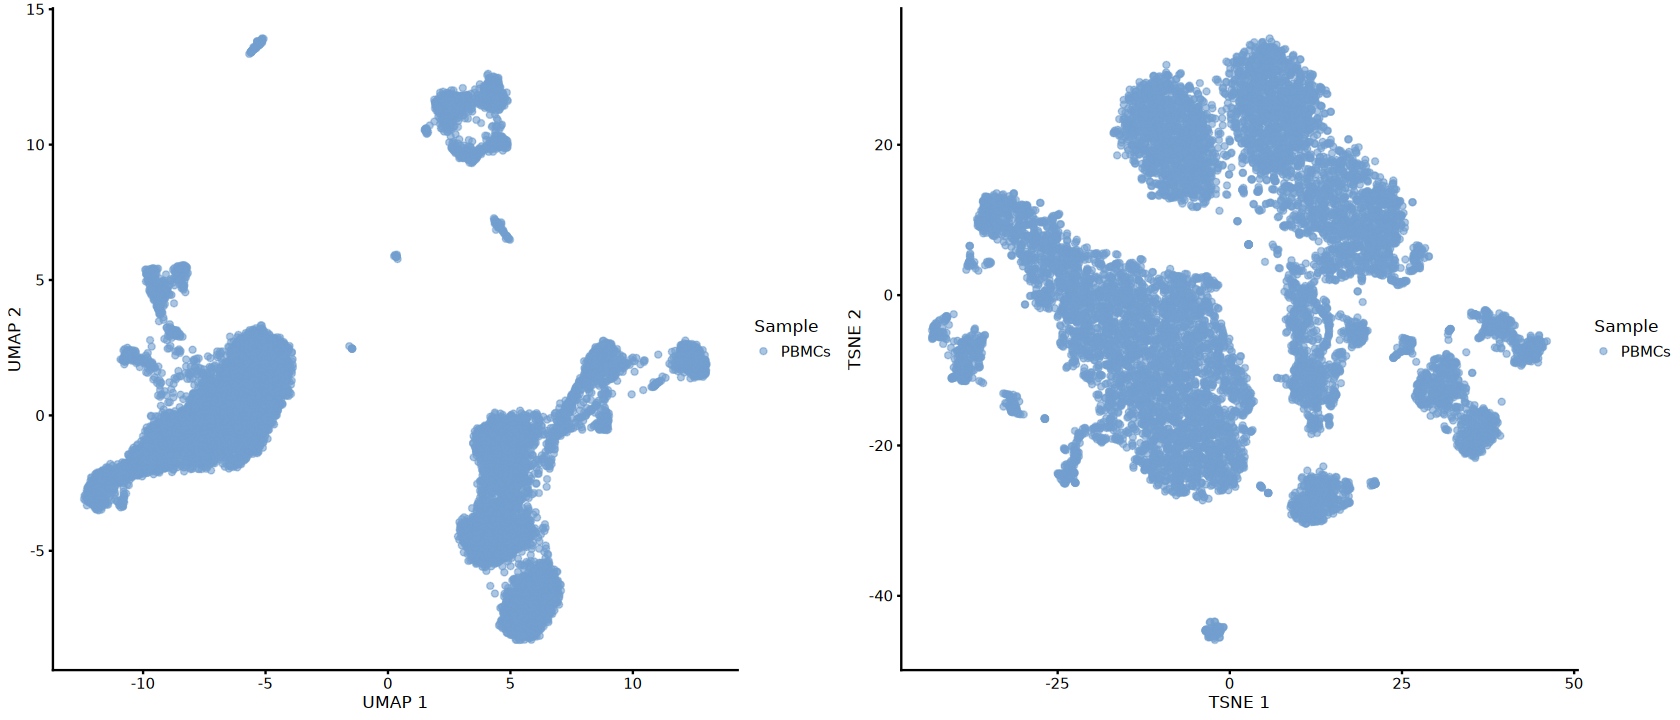

In [99]:
p1 <- plotReducedDim(scrna, dimred = "UMAP", color_by = "Sample")
p2 <- plotReducedDim(scrna, dimred = "TSNE", color_by = "Sample")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 5. Batch correction (Skip)

In [ ]:
library(batchelor)

In [ ]:
set.seed(123)
sce <- correctExperiments(sce, batch=sce$individual, 
    subset.row=hvg, correct.all=TRUE)

# 6. Clustering

In [109]:
set.seed(123)
colLabels(scrna) <- clusterCells(
    scrna, use.dimred = 'PCA', 
    BLUSPARAM = NNGraphParam(k = 50, type = "number"))   

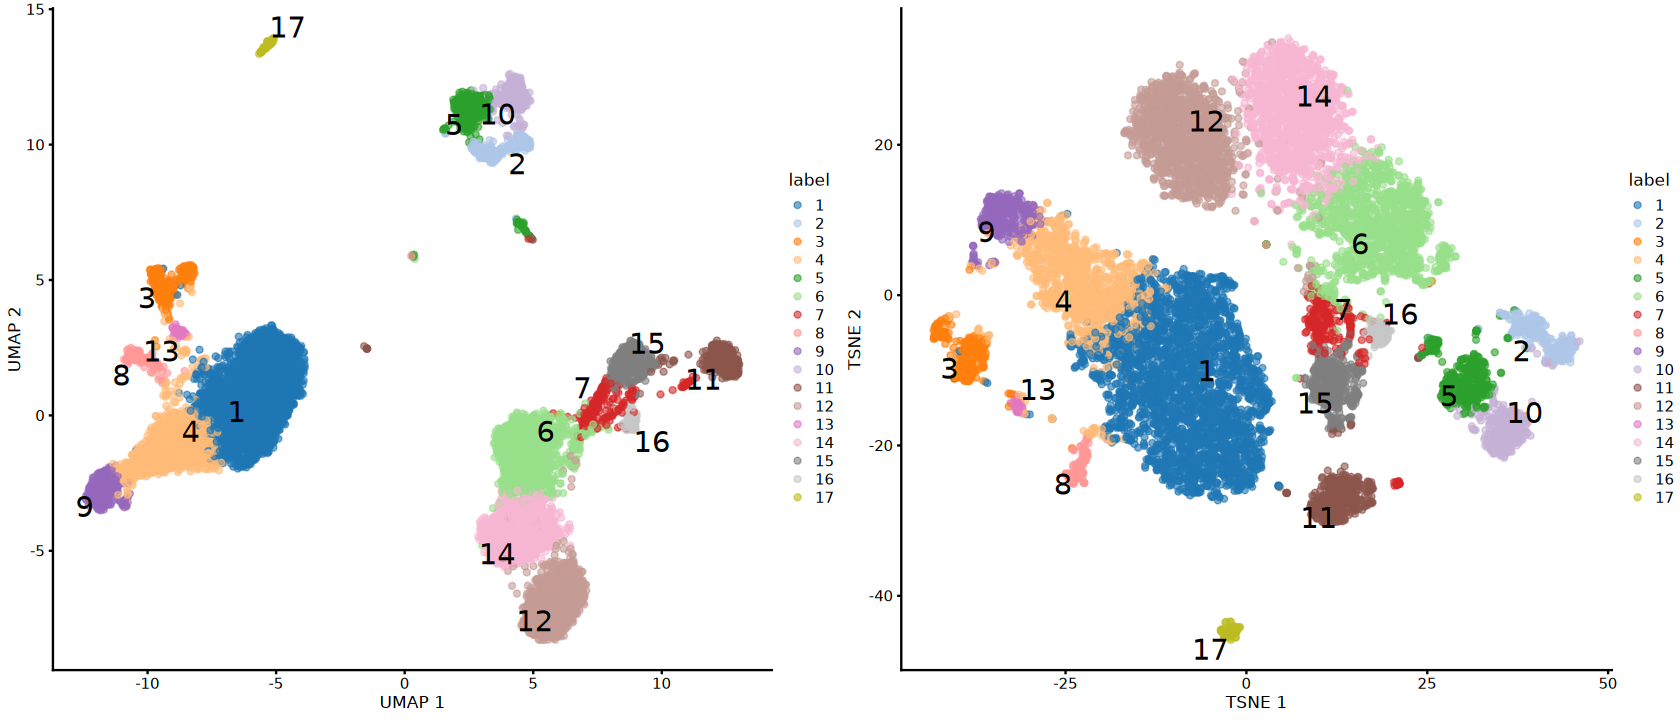

In [110]:
p1 <- plotReducedDim(
    scrna, dimred = "UMAP", color_by = "label",
    text_by="label", text_size = 6)
p2 <- plotReducedDim(
    scrna, dimred = "TSNE", color_by = "label", 
    text_by="label", text_size = 6)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [111]:
set.seed(123)
colLabels(scrna) <- clusterCells(
    scrna, use.dimred = 'PCA', 
    BLUSPARAM = NNGraphParam(cluster.fun = "louvain"))

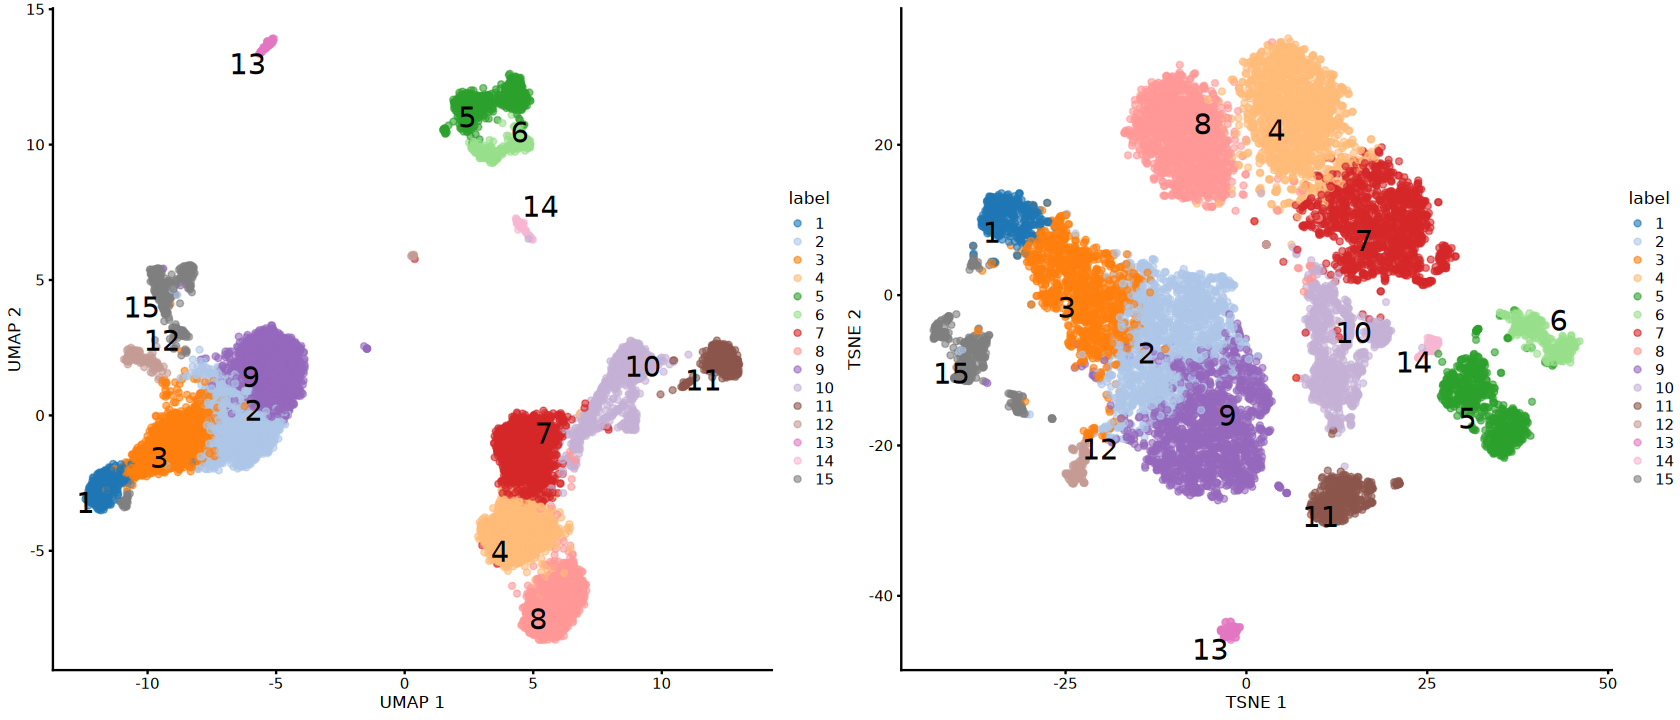

In [112]:
p1 <- plotReducedDim(
    scrna, dimred = "UMAP", color_by = "label",
    text_by="label", text_size = 6)
p2 <- plotReducedDim(
    scrna, dimred = "TSNE", color_by = "label", 
    text_by="label", text_size = 6)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [113]:
set.seed(123)
colLabels(scrna) <- clusterCells(
    scrna, use.dimred = "PCA", 
    BLUSPARAM = KmeansParam(centers = 10))

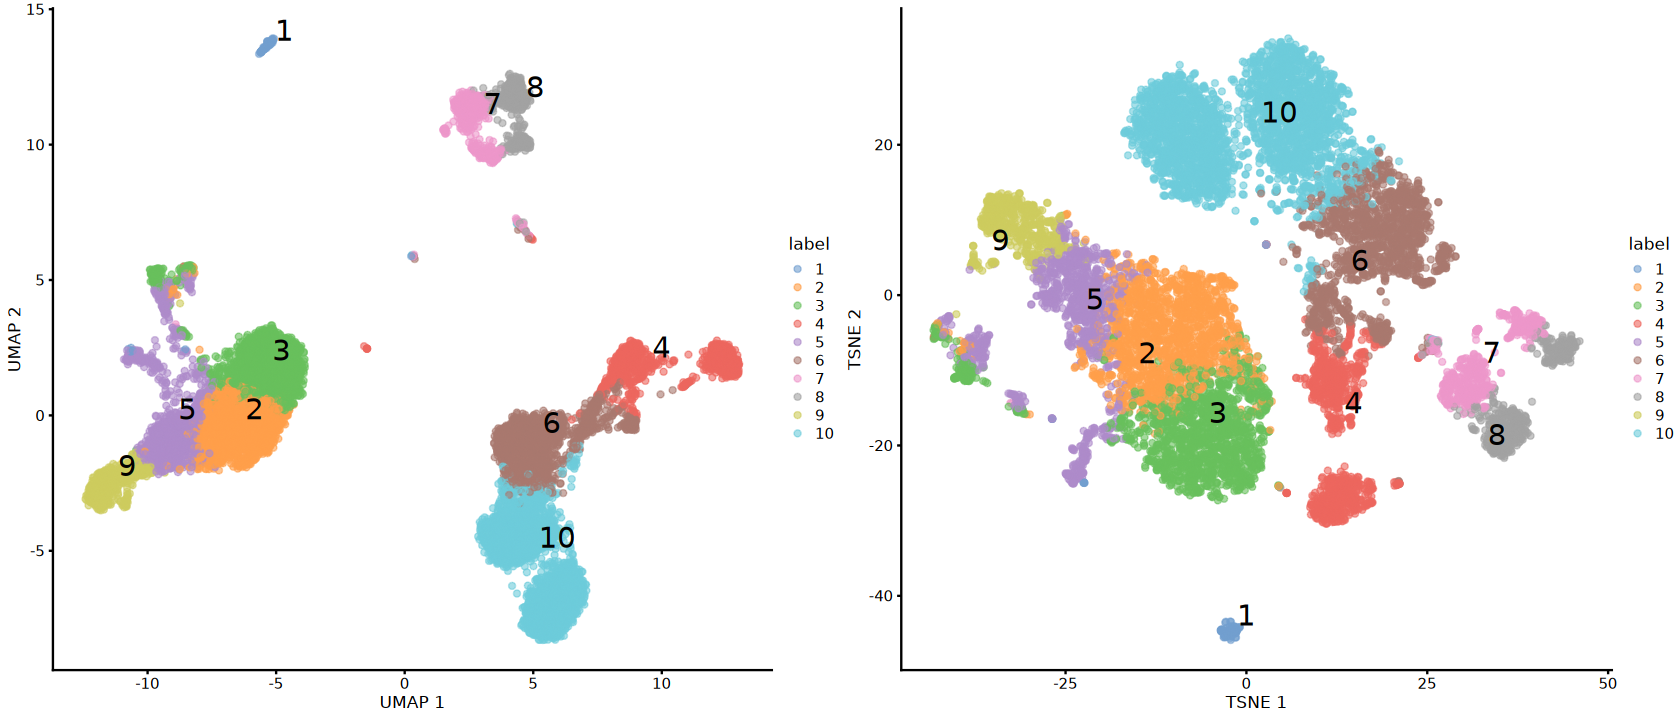

In [114]:
p1 <- plotReducedDim(
    scrna, dimred = "UMAP", color_by = "label",
    text_by="label", text_size = 6)
p2 <- plotReducedDim(
    scrna, dimred = "TSNE", color_by = "label", 
    text_by="label", text_size = 6)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [115]:
set.seed(123)
colLabels(scrna) <- clusterCells(
    scrna, use.dimred = "PCA", 
    BLUSPARAM = TwoStepParam(
        first = KmeansParam(centers = 1000),
        second = NNGraphParam(k = 5)))

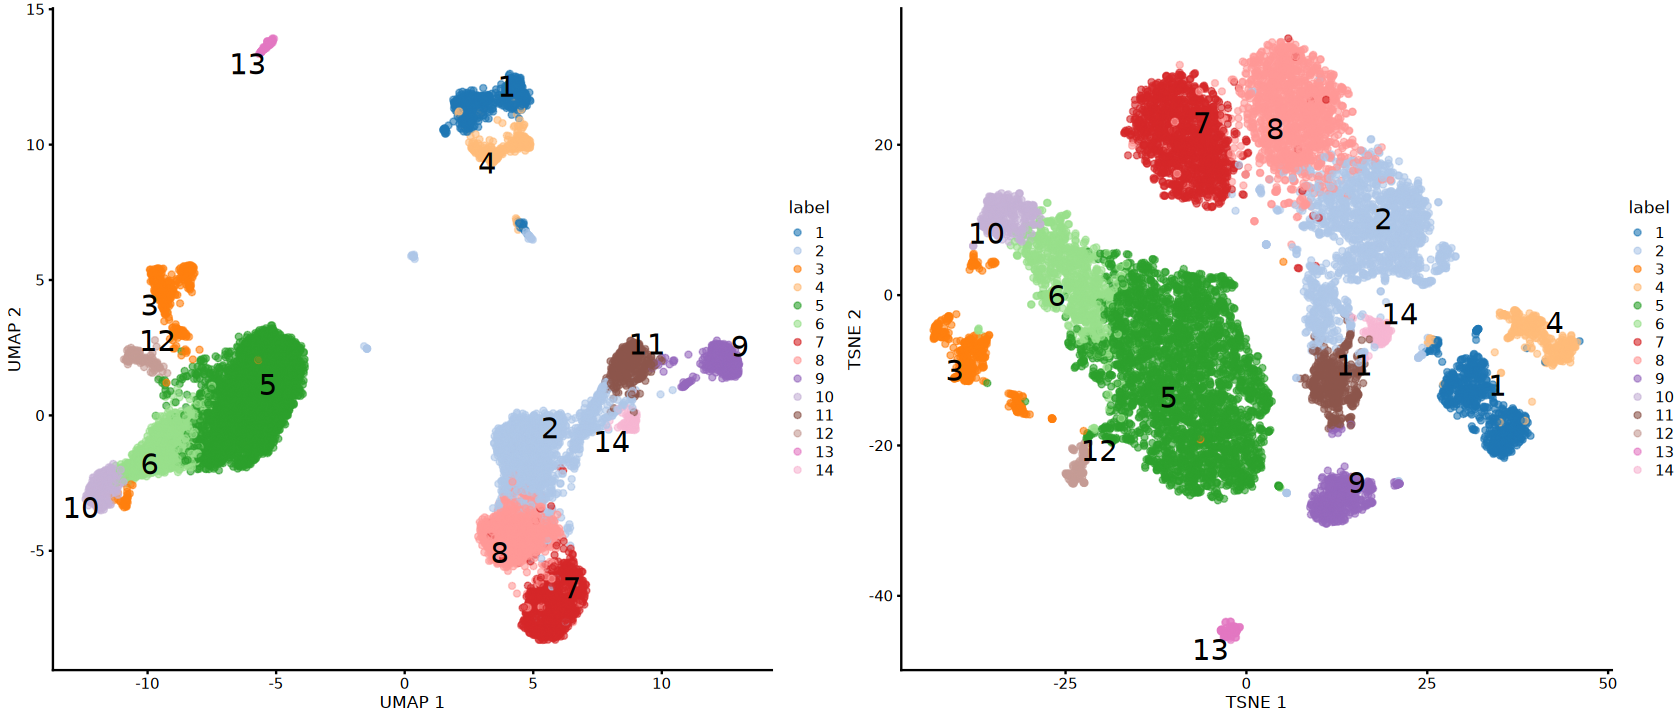

In [116]:
p1 <- plotReducedDim(
    scrna, dimred = "UMAP", color_by = "label",
    text_by="label", text_size = 6)
p2 <- plotReducedDim(
    scrna, dimred = "TSNE", color_by = "label", 
    text_by="label", text_size = 6)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 7. Cluster Biomarkers

In [ ]:
# Marker detection.
markers <- findMarkers(sce, test.type="wilcox", direction="up", lfc=1)

# inferring cell cycle

In [ ]:
rm(list = ls())

library(scran)
library(org.Mm.eg.db)
library(scatterplot3d)
library(pheatmap)

exprMat[1:6, 1:4]
dim(exprMat)

sce <- SingleCellExperiment(list(counts = exprMat))

mm.pairs <- readRDS(system.file("exdata", "mouse_cycle_markers.rds", package="scran"))
ensembl <- mapIds(org.Mm.eg.db, keys=rownames(sce), keytype="SYMBOL", column="ENSEMBL")
# inferring cell cycle
assigned <- cyclone(sce, pairs=mm.pairs, gene.names=ensembl)

table(assigned$phases)
head(assigned$scores)
draw <- cbind(assigned$score,assigned$phases)
attach(draw) # ?attach
scatterplot3d(G1, S, G2M, angle=20,
              color = rainbow(3)[as.numeric(as.factor(assigned$phases))],
              grid=TRUE, box=FALSE)
detach(draw)

cg <- names(tail(sort(apply(exprMat,1,sd)),100))
tmp <- t(scale(t(exprMat[cg,])))
ac <- data.frame(cellcycle=assigned$phases)
rownames(ac) <- colnames(tmp)
pheatmap(tmp, show_colnames=F, show_rownames=F, annotation_col=ac)
